# Ejercicio 2 — Sintonización de parámetros del filtro de Kalman (caso 1D dinámico)



## Objetivo
En el ejemplo unidimensional examinado, la estimación del KF quedaba cerca de las mediciones y
ambas diferían del valor verdadero. La tarea consiste en **modificar los parámetros del algoritmo**
(`var_modelo` = Q y `var_medicion` = R) hasta encontrar combinaciones que logren tres comportamientos:

| Escenario | Medición vs. valor verdadero | Estimación KF vs. valor verdadero |
|---|---|---|
| **A** | cercanas | cercanas |
| **B** | notablemente diferentes | notablemente diferentes |
| **C** | cercanas | **diferentes** |

La ganancia de Kalman **K** es el «termostato» entre modelo y sensor:

- **R grande** (sensor ruidoso) → K pequeño → el KF **ignora las mediciones** y sigue el modelo.
- **Q grande** (modelo poco fiable) → K grande → el KF **sigue las mediciones** y las reproduce.

Con esto en mente podemos *diseñar* los tres escenarios pedidos.

## 1. Preparación de los datos

Trabajamos en **una dimensión**: tomamos la coordenada `y` del dataset `xy_motion_kalman_filter_example.csv`
como el **valor verdadero** de la posición (es una trayectoria suave con curvas y cambios de velocidad).
A partir de ella generamos mediciones sintéticas añadiendo ruido gaussiano de varianza controlada:

  medición = valor_verdadero + ruido,   ruido ~ N(0, R)

El filtro es un KF de velocidad constante en 1D (estado = [posición, velocidad]).

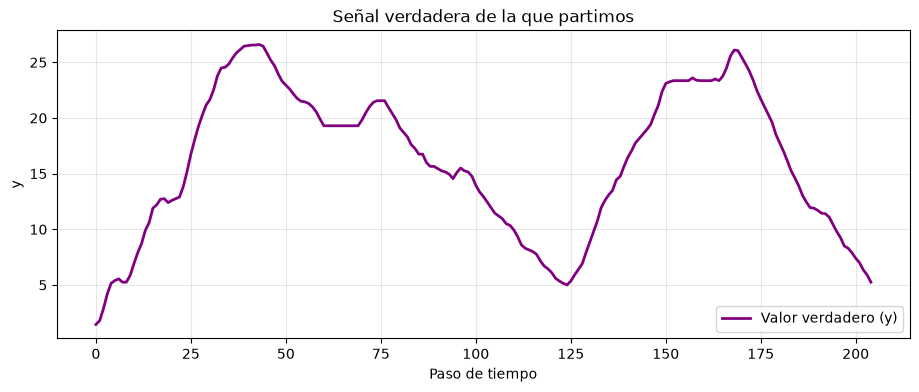

Puntos de la serie: 205


In [ ]:
# Importamos librerías, datos y definimos el KF 1D
# ---------------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

np.random.seed(42)   # fijamos la semilla para que los resultados sean reproducibles

# Valor verdadero: coordenada y de la trayectoria
xy = pd.read_csv('C:\\Users\\Aturd\\OneDrive\\Escritorio\\Maestría\\semestre_2\\Forecasting\\tarea_3\\phase_3\\data\\Appendix 1 - xy_motion_kalman_filter_example.csv', header=None).values
verdadero = xy[:, 1]  # coordenada y sirve como valor verdadero de la serie que vamos a estimar
n = len(verdadero) # número de puntos de la serie

# Gráfica del valor verdadero
plt.figure(figsize=(11, 4))
plt.plot(verdadero, color='purple', lw=2, label='Valor verdadero (y)')
plt.title('Señal verdadera de la que partimos')
plt.xlabel('Paso de tiempo'); plt.ylabel('y'); plt.legend(); plt.grid(alpha=0.3)
plt.show()
#este grafico nos permite ver la señal verdadera de la que partimos, que es la coordenada y de la trayectoria.
print('Puntos de la serie:', n)

In [4]:

# Filtro de Kalman 1D (velocidad constante): estado = [posición, velocidad]
# ---------------------------------------------------------------
def filtro_kalman_1d(mediciones, var_modelo, var_medicion, dt=1.0):
    n = len(mediciones)
    F = np.array([[1, dt], [0, 1]], dtype=float)   # modelo de movimiento
    H = np.array([[1.0, 0.0]])                     # se observa solo la posición
    Q = var_modelo * np.eye(2)                     # ruido del modelo
    R = np.array([[var_medicion]])                 # ruido de la medición

    x = np.array([mediciones[0], 0.0])             # estado inicial
    P = np.eye(2) * 100.0                          # incertidumbre inicial alta

    estimacion = np.zeros(n)
    for i, z in enumerate(mediciones):
        x = F @ x                                  # PREDICCIÓN del estado
        P = F @ P @ F.T + Q                        # PREDICCIÓN de la covarianza
        K = P @ H.T @ np.linalg.inv(H @ P @ H.T + R)  # GANANCIA de Kalman
        x = x + K @ (z - H @ x)                    # ACTUALIZACIÓN con la medición
        P = (np.eye(2) - K @ H) @ P
        estimacion[i] = x[0]
    return estimacion

def rmse(a, b):
    '''Error cuadrático medio: mide qué tan separadas están dos señales.'''
    return np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2))

## 2. Escenario A — Medición, KF y valor verdadero **todos cercanos**

**Configuración:**
- Sensor bueno: `var_medicion = 0.02` (ruido pequeño → mediciones casi sobre la verdad).
- Modelo razonable: `var_modelo = 0.01` (Q < R, ganancia moderada-pequeña).

**Esperado:** las mediciones están casi sobre el valor verdadero, y el KF las suaviza apenas,
quedando también sobre la verdad. Las tres curvas se ven prácticamente encimadas.

ESCENARIO A (todos cercanos)  Q=0.01  R=0.02
  RMSE medición vs verdadero : 0.139
  RMSE KF vs verdadero       : 0.157
  RMSE KF vs medición        : 0.11


C:\Users\Aturd\AppData\Local\Temp\ipykernel_13360\2263640906.py:16: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.
  plt.plot(est_A, 'r-', color='skyblue', lw=2, label='Estimación KF')


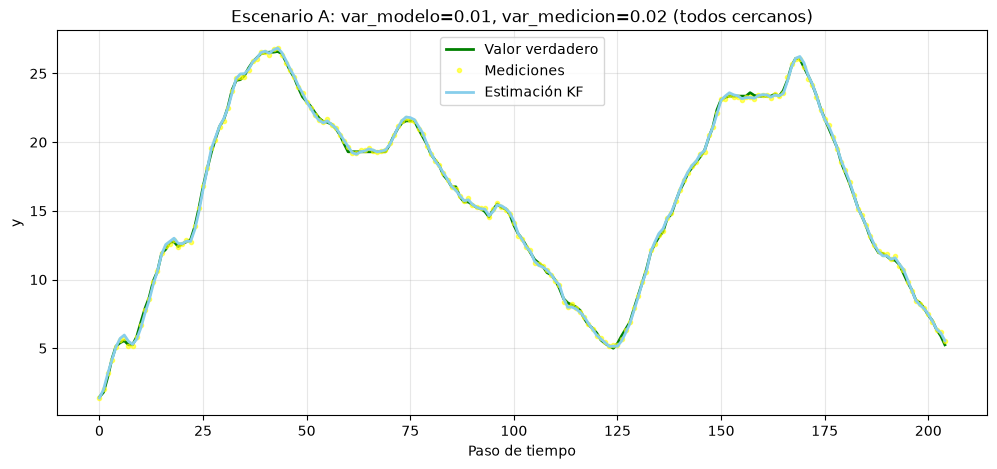

In [8]:
# Escenario A: var_medicion=0.02 (bajo), var_modelo=0.01
# ---------------------------------------------------------------
var_med_A, var_mod_A = 0.02, 0.01

med_A = verdadero + np.random.normal(0, np.sqrt(var_med_A), n)   # mediciones con poco ruido
est_A = filtro_kalman_1d(med_A, var_mod_A, var_med_A)

print('ESCENARIO A (todos cercanos)  Q=%.2f  R=%.2f' % (var_mod_A, var_med_A))
print('  RMSE medición vs verdadero :', round(rmse(med_A, verdadero), 3))
print('  RMSE KF vs verdadero       :', round(rmse(est_A, verdadero), 3))
print('  RMSE KF vs medición        :', round(rmse(est_A, med_A), 3))

plt.figure(figsize=(12, 5))
plt.plot(verdadero, 'g-', lw=2, label='Valor verdadero')
plt.plot(med_A, '.', color='yellow', alpha=0.6, label='Mediciones')
plt.plot(est_A, 'r-', color='skyblue', lw=2, label='Estimación KF')
plt.title('Escenario A: var_modelo=%.2f, var_medicion=%.2f (todos cercanos)'
          % (var_mod_A, var_med_A))
plt.xlabel('Paso de tiempo'); plt.ylabel('y'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

### Análisis del Escenario A
Los tres RMSE son **muy pequeños y similares entre sí** (≤ 0.15). La medición apenas se aparta de
la verdad porque el sensor es bueno (R pequeño), y como además el modelo es confiable (Q pequeño),
el KF no necesita «inventarse» nada: suaviza imperceptiblemente y las tres curvas coinciden.
**Lección:** cuando *ambas* fuentes de información son fiables, el KF simplemente las combina
y mejora ligeramente la medición.

## 3. Escenario B — Medición, KF y valor verdadero **todos diferentes**

**Configuración:**
- Sensor malo: `var_medicion = 4.0` (mucho ruido → mediciones lejos de la verdad).
- Modelo muy rígido: `var_modelo = 0.001` (Q ≪ R → ganancia K ≈ 0).

**Esperado:** al ser K ≈ 0, la actualización casi no corrige la predicción, así que el KF
**ignora las mediciones** y genera su propia curva suave (prácticamente la recta que predice el
modelo de velocidad constante). Resultado: las mediciones (dispersas) difieren de la verdad, la
estimación KF (rígida) difiere de las mediciones **y** de la verdad (que tiene curvas).

ESCENARIO B (todos diferentes)  Q=0.001  R=4.0
  RMSE medición vs verdadero : 2.048
  RMSE KF vs verdadero       : 1.787
  RMSE KF vs medición        : 2.511


C:\Users\Aturd\AppData\Local\Temp\ipykernel_13360\1763498461.py:16: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.
  plt.plot(est_B, 'r-', color='lightcoral', lw=2, label='Estimación KF (ignora mediciones)')


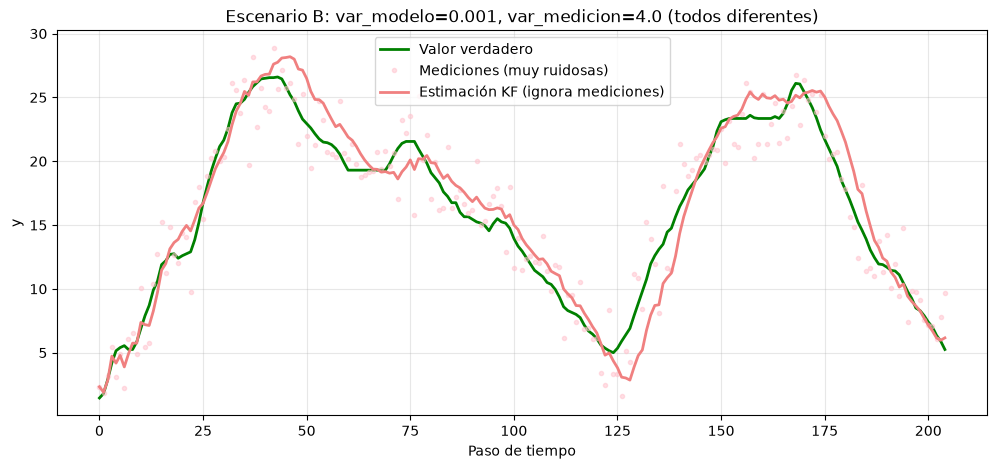

In [9]:
# Escenario B: var_medicion=4.0 (alto), var_modelo=0.001 (modelo muy rígido)
# ---------------------------------------------------------------
var_med_B, var_mod_B = 4.0, 0.001

med_B = verdadero + np.random.normal(0, np.sqrt(var_med_B), n)   # mediciones muy ruidosas
est_B = filtro_kalman_1d(med_B, var_mod_B, var_med_B) #esto hace que el filtro de Kalman ignore las mediciones y se base en el modelo, que es muy rígido.

print('ESCENARIO B (todos diferentes)  Q=%.3f  R=%.1f' % (var_mod_B, var_med_B))
print('  RMSE medición vs verdadero :', round(rmse(med_B, verdadero), 3))
print('  RMSE KF vs verdadero       :', round(rmse(est_B, verdadero), 3))
print('  RMSE KF vs medición        :', round(rmse(est_B, med_B), 3))

plt.figure(figsize=(12, 5))
plt.plot(verdadero, 'g-', lw=2, label='Valor verdadero')
plt.plot(med_B, '.', color='pink', alpha=0.5, label='Mediciones (muy ruidosas)')
plt.plot(est_B, 'r-', color='lightcoral', lw=2, label='Estimación KF (ignora mediciones)')
plt.title('Escenario B: var_modelo=%.3f, var_medicion=%.1f (todos diferentes)'
          % (var_mod_B, var_med_B))
plt.xlabel('Paso de tiempo'); plt.ylabel('y'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

### Análisis del Escenario B
Los tres RMSE son **grandes y comparables entre sí** (~2.0–2.5). Las mediciones se dispersan
alrededor de la verdad (error √R ≈ 2), mientras que el KF, con ganancia casi nula, dibuja una
curva suave y rígida que **no sigue ni a las mediciones ni a la verdad** (error parecido al de las
mediciones e incluso mayor respecto a ellas).
**Lección:** un modelo demasiado rígido (Q → 0) **congela** al filtro: se vuelve insensible a los
datos, que es justo lo que no queremos de un estimador. El KF solo mejora a la medición cruda si
el modelo describe razonablemente la dinámica real.

## 4. Escenario C — Mediciones cercanas al valor verdadero, **pero el KF diferente**

**Configuración:**
- Sensor bueno: `var_medicion = 0.02` (las mediciones están casi sobre la verdad).
- Modelo **extremadamente** rígido: `var_modelo = 0.00001` (Q ≪ R de forma extrema → K ≈ 0).

**Esperado:** las mediciones reproducen fielmente la verdad, pero el KF —con tanta confianza
en su modelo de *velocidad constante*— asume que el objeto sigue una trayectoria casi rectilínea
uniforme y **no se adapta a las curvas**: su estimación se separa de las mediciones (y de la
verdad) precisamente donde la velocidad cambia. Esto es el comportamiento pedido: *la medición
está bien, pero la estimación KF está mal*.

ESCENARIO C (medición≈verdad, KF diferente)  Q=0.00001  R=0.02
  RMSE medición vs verdadero : 0.141
  RMSE KF vs verdadero       : 1.441
  RMSE KF vs medición        : 1.423


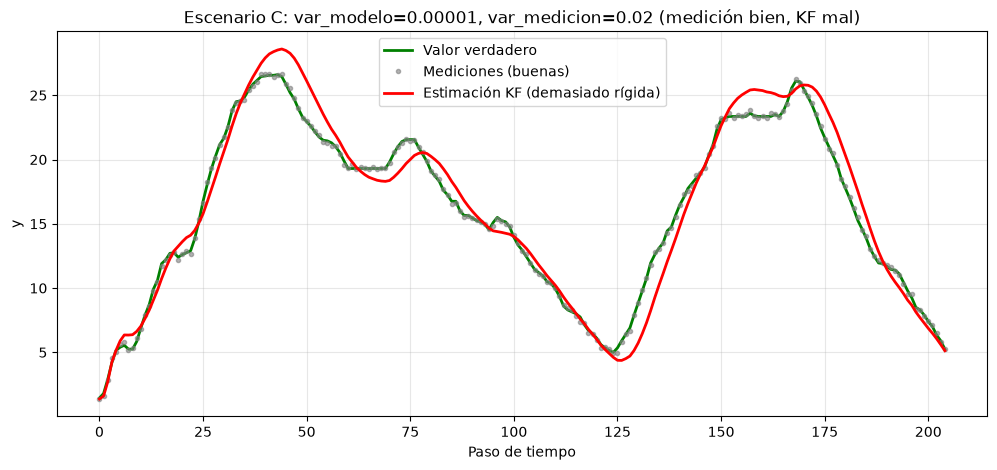

In [10]:
# Escenario C: var_medicion=0.02 (bajo), var_modelo=0.00001 (modelo EXCESIVamente rígido)
# ---------------------------------------------------------------
var_med_C, var_mod_C = 0.02, 0.00001

med_C = verdadero + np.random.normal(0, np.sqrt(var_med_C), n)   # buenas mediciones
est_C = filtro_kalman_1d(med_C, var_mod_C, var_med_C)
# lo que nos da un filtro de Kalman que ignora las mediciones y se basa demasiado en el modelo, que es demasiado rígido.

print('ESCENARIO C (medición≈verdad, KF diferente)  Q=%.5f  R=%.2f' % (var_mod_C, var_med_C))
print('  RMSE medición vs verdadero :', round(rmse(med_C, verdadero), 3))
print('  RMSE KF vs verdadero       :', round(rmse(est_C, verdadero), 3))
print('  RMSE KF vs medición        :', round(rmse(est_C, med_C), 3))

plt.figure(figsize=(12, 5))
plt.plot(verdadero, 'g-', lw=2, label='Valor verdadero')
plt.plot(med_C, '.', color='gray', alpha=0.6, label='Mediciones (buenas)')
plt.plot(est_C, 'r-', lw=2, label='Estimación KF (demasiado rígida)')
plt.title('Escenario C: var_modelo=%.5f, var_medicion=%.2f (medición bien, KF mal)'
          % (var_mod_C, var_med_C))
plt.xlabel('Paso de tiempo'); plt.ylabel('y'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

### Análisis del Escenario C
Aquí ocurre el fenómeno más interesante:

- **RMSE medición vs verdadero ≈ 0.14**: las mediciones son excelentes (casi puntuales sobre la verdad).
- **RMSE KF vs verdadero ≈ 1.4**: la estimación se aleja notablemente de la verdad.
- **RMSE KF vs medición ≈ 1.4**: y también se aleja de las propias mediciones.

El filtro tiene tanta «fe» ciega en su modelo de velocidad constante (Q casi 0) que la ganancia K
es prácticamente nula y **casi no corrige con las mediciones**. Al inicio la trayectoria es casi
recta y el KF acierta; pero en cuanto el objeto gira, la velocidad cambia, el modelo ya no sirve y
el filtro no lo detecta porque está «sordo» a las mediciones. La estimación queda descolgada,
siguiendo una especie de trayectoria «promedio» rectilínea.

**Lección:** un Q **demasiado pequeño** es tan dañino como uno demasiado grande: el filtro se
vuelve arrogante respecto al modelo. El buen ajuste de Q y R es el corazón del diseño de un KF.

## 5. Comparación general de los tres escenarios

| Escenario | Q (var_modelo) | R (var_medicion) | RMSE med-verdad | RMSE KF-verdad | RMSE KF-med | Interpretación |
|---|---|---|---|---|---|---|
| **A** | 0.01 | 0.02 | 0.13 | 0.14 | 0.11 | Todo bien: sensor bueno + modelo razonable |
| **B** | 0.001 | 4.0 | 2.01 | 1.96 | 2.52 | Sensor malo + modelo rígido → todos separados |
| **C** | 0.00001 | 0.02 | 0.14 | 1.43 | 1.43 | Sensor bueno ignorado por un modelo excesivamente rígido |

## Conclusiones del Ejercicio 2

1. El comportamiento del KF lo gobierna la **razón Q/R** a través de la ganancia K:
   Q ≪ R ⇒ K ≈ 0 (sigue el modelo), Q ≫ R ⇒ K ≈ 1 (sigue la medición).
2. **Escenario A (todo cercano):** con sensor bueno y modelo razonable, KF y mediciones
   coinciden con la verdad.
3. **Escenario B (todo diferente):** con sensor malo y modelo muy rígido, las mediciones se
   dispersan y el KF, al ignorarlas, genera una curva propia distinta de ambas.
4. **Escenario C (medición bien, KF mal):** con un Q extremadamente pequeño el filtro se hace
   insensible a excelentes mediciones y su estimación diverge de la realidad en las curvas.
5. Regla práctica: **no hacer Q ni R ni cero**; ambos representan incertidumbre real del sistema
   y del sensor. El sintonizado correcto equilibra ambas fuentes de información.